In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator as rdf
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
import keras

Loading the data and checking it

In [2]:
df = pd.read_csv('CH_borylation_ChemAI_assessment.csv')
df.head(5)

,rxn_id,substrate_smiles,substrate_smiles_mapped,temperature_degC,solvent_1_smiles,solvent_1_fraction,solvent_2_smiles,solvent_2_fraction,catalyst_1_smiles,catalyst_2_smiles,...,reagent_2_smiles,reagent_3_smiles,reagent_4_smiles,total_yield,product_smiles,product_smiles_mapped,site,yield,regio_fraction,source_DOI
0,lit_pub_bo_1075,COc1cccc(OC)c1OC,[CH3:1][O:2][c:3]1[cH:4][cH:5][cH:6][c:7]([O:8...,80,O1CCCC1,1.0,NaN,NaN,[O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7...,NaN,...,NaN,NaN,NaN,0.74,COc1cc(B2OC(C)(C)C(C)(C)O2)cc(OC)c1OC,[CH3:1][O:2][c:3]1[cH:4][c:5]([B:6]2[O:7][C:8]...,5,0.74,1.0,10.1021/ja400295v
1,lit_pub_bo_109,CN(C)c1ccccc1,[CH3:1][N:2]([CH3:3])[c:4]1[cH:5][cH:6][cH:7][...,100,ClC=1C=CC=CC1Cl,1.0,NaN,NaN,FC=1C(F)=C(F)C(B(C=2C(F)=C(F)C(F)=C(F)C2F)C=3C...,NaN,...,N(CC)(CC)CC,OC(C)(C)C(O)(C)C,NaN,0.98,CN(C)c1ccc(B2OC(C)(C)C(C)(C)O2)cc1,[CH3:1][N:2]([CH3:3])[c:4]1[cH:5][cH:6][c:7]([...,7,0.98,1.0,10.1002/anie.201611536
2,lit_pub_bo_1125,Cc1cccc(Br)c1,[CH3:1][c:2]1[cH:3][cH:4][cH:5][c:6]([Br:7])[c...,25,N(CC)(CC)CC,1.0,NaN,NaN,[O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7...,NaN,...,NaN,NaN,NaN,0.35,Cc1cc(Br)cc(B2OC(C)(C)C(C)(C)O2)c1,[CH3:1][c:2]1[cH:3][c:4]([Br:5])[cH:6][c:7]([B...,4,0.35,1.0,10.1021/ja400295v
3,lit_pub_bo_114,c1ccc(N2CCCC2)cc1,[cH:1]1[cH:2][cH:3][c:4]([N:5]2[CH2:6][CH2:7][...,120,C=1C=CC(=CC1)C,1.0,NaN,NaN,FC=1C(F)=C(F)C(B(C=2C(F)=C(F)C(F)=C(F)C2F)C=3C...,NaN,...,N(CC)(CC)CC,OC(C)(C)C(O)(C)C,NaN,0.92,CC1(C)OB(c2ccc(N3CCCC3)cc2)OC1(C)C,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,1,0.92,1.0,10.1002/anie.201611536
4,lit_pub_bo_115,CN(c1ccccc1)c1ccccc1,[CH3:1][N:2]([c:3]1[cH:4][cH:5][cH:6][cH:7][cH...,120,C=1C=CC(=CC1)C,1.0,NaN,NaN,FC=1C(F)=C(F)C(B(C=2C(F)=C(F)C(F)=C(F)C2F)C=3C...,NaN,...,N(CC)(CC)CC,OC(C)(C)C(O)(C)C,NaN,0.35,CN(c1ccccc1)c1ccc(B2OC(C)(C)C(C)(C)O2)cc1,[CH3:1][N:2]([c:3]1[cH:4][cH:5][cH:6][cH:7][cH...,12,0.35,1.0,10.1002/anie.201611536


In [3]:
list(df['source_DOI'].value_counts().keys())

['10.1002/anie.201708967',
 '10.1038/nchem.2322',
 '10.1038/s41586-019-1640-2',
 '10.1002/anie.201809929',
 '10.1039/c2sc20776a',
 '10.1021/jacs.7b04490',
 '10.1021/jacs.5b02052',
 '10.1002/anie.201509996',
 '10.1002/anie.201610041',
 '10.1126/science.aba6146',
 '10.1002/anie.201907366',
 '10.1021/jacs.5b11683',
 '10.1021/jacs.7b02232',
 '10.1021/jacs.5b05252',
 '10.1021/jacs.6b13346',
 '10.1021/ja412563e',
 '10.1002/anie.201104544',
 '10.1021/ja303443m',
 '10.1002/anie.201611536',
 '10.1021/ja2097095',
 '10.1021/jacs.6b13389',
 '10.1021/ja0428309',
 '10.1021/jacs.5b07154',
 '10.1021/ja1006405',
 '10.1021/jacs.0c05434',
 '10.1021/ja0631652',
 '10.1021/jacs.5b07677',
 '10.1021/ja500712z',
 '10.1126/science.abc8320',
 '10.1021/jacs.7b08143',
 '10.1002/anie.201909786',
 '10.1021/ja400295v',
 '10.1021/jacs.5b04899',
 '10.1021/jacs.9b08920',
 '10.1002/anie.201409186',
 '10.1021/acscatal.0c00152']

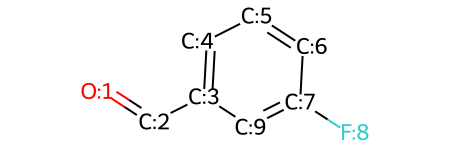

In [4]:
id = 200
rdmol1 = Chem.MolFromSmiles(df.loc[id, 'substrate_smiles_mapped'])
rdmol1

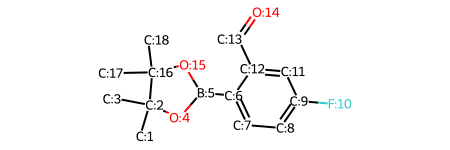

In [5]:
rdmol1 = Chem.MolFromSmiles(df.loc[id, 'product_smiles_mapped'])
rdmol1

In [6]:
print('Non-null substrates/products: ', df['substrate_smiles_mapped'].notnull().sum(), '/', df['product_smiles_mapped'].notnull().sum())

Non-null substrates/products:  744 / 744


The very first idea: look at every C-H bond in the molecule and try to train a model to predict the most probable one to undergo borrylation. For this, we first idendify the candidates - all carbons that are connected to at least one hydrogen:

In [7]:
def get_borrylation_candidates_from_smiles(smiles_):
    mol = Chem.MolFromSmiles(smiles_)
    mol = Chem.AddHs(mol)
    cs = []
    for atom in mol.GetAtoms():
        if atom.GetAtomicNum() == 6:
            for neighbor in atom.GetNeighbors():
                if neighbor.GetAtomicNum() == 1 and atom.GetIdx() not in cs:
                    cs.append(atom)
    return cs 


Check:

In [8]:
candidates = get_borrylation_candidates_from_smiles(df.loc[id, 'substrate_smiles_mapped'])
for candidate in candidates:
    print(f'Candidate idx = {candidate.GetIdx()}, Mapno = {candidate.GetAtomMapNum()}')

Candidate idx = 1, Mapno = 2
Candidate idx = 3, Mapno = 4
Candidate idx = 4, Mapno = 5
Candidate idx = 5, Mapno = 6
Candidate idx = 8, Mapno = 9


Now extend this to the entire dataframe, also keeping track of which carbons

In [9]:
df_new = pd.DataFrame()
ids = []

for i, smiles in enumerate(df['substrate_smiles_mapped'].values):
    candidates = get_borrylation_candidates_from_smiles(smiles)
    idxs = [candidate.GetIdx() for candidate in candidates]
    mapnos = [candidate.GetAtomMapNum() for candidate in candidates]
    smiles_list = [smiles] * len(candidates)
    ids = ids + [i] * len(candidates)
    temp = pd.DataFrame({'substrate_smiles_mapped': smiles_list, 'candidate_idx': idxs, 'candidate_mapno': mapnos})
    temp['reacted'] = temp['candidate_mapno'] == df['site'].values[i]
    df_new = pd.concat([df_new, temp], ignore_index=True)

df_new['id'] = ids

In [10]:
#df_new['rxn_id'] = df['source_DOI']
df_new

,substrate_smiles_mapped,candidate_idx,candidate_mapno,reacted,id
0,[CH3:1][O:2][c:3]1[cH:4][cH:5][cH:6][c:7]([O:8...,0,1,False,0
1,[CH3:1][O:2][c:3]1[cH:4][cH:5][cH:6][c:7]([O:8...,0,1,False,0
2,[CH3:1][O:2][c:3]1[cH:4][cH:5][cH:6][c:7]([O:8...,0,1,False,0
3,[CH3:1][O:2][c:3]1[cH:4][cH:5][cH:6][c:7]([O:8...,3,4,False,0
4,[CH3:1][O:2][c:3]1[cH:4][cH:5][cH:6][c:7]([O:8...,4,5,True,0
...,...,...,...,...,...
9612,[CH3:1][CH:2]([CH3:3])[c:4]1[cH:5][cH:6][cH:7]...,9,10,False,743
9613,[CH3:1][CH:2]([CH3:3])[c:4]1[cH:5][cH:6][cH:7]...,10,11,False,743
9614,[CH3:1][CH:2]([CH3:3])[c:4]1[cH:5][cH:6][cH:7]...,10,11,False,743
9615,[CH3:1][CH:2]([CH3:3])[c:4]1[cH:5][cH:6][cH:7]...,10,11,False,743


### Now let us generate fingerprints for each atom:

In [11]:
l_fp = 64

In [12]:
def generate_fingerprint_starting_from_i(smiles_, i_, radius_ = 2, nbits_ = 256):
    mol = Chem.MolFromSmiles(smiles_)
    generator = rdf.GetMorganGenerator(radius = radius_, fpSize = nbits_)
    fp = generator.GetFingerprintAsNumPy(mol, fromAtoms = [i_])
    return fp

def generate_other_descriptors(smiles_, i_):
    mol = Chem.MolFromSmiles(smiles_)
    atom = mol.GetAtomWithIdx(i_)
    
    return [atom.GetDegree(), atom.GetTotalNumHs()]

In [ ]:
df_new['fingerprint'] = df_new.apply(lambda row: generate_fingerprint_starting_from_i(row['substrate_smiles_mapped'], row['candidate_idx'], nbits_ = l_fp), axis=1)

In [ ]:
fingerprint_matrix = np.array(df_new['fingerprint'].values.tolist())
fingerprint_matrix.shape

(9617, 64)

In [ ]:
for i, col in enumerate(fingerprint_matrix.T):
    df_new[f'fp_{i}'] = col

### Now, it is high-time to test the very basic model:

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = []
X = df_new[[f'fp_{i}' for i in range(l_fp)]]
y = df_new['reacted']

for train_idx, val_idx in skf.split(X, y):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
    
    model = RandomForestClassifier(random_state=42)
    model.fit(X_train, y_train)
    preds = model.predict(X_val)
    scores.append(f1_score(y_val, preds))

print(f'Final f1 score is {np.mean(scores):.3f}')

Final f1 score is 0.188


### Let us try to complicate it a bit: let the model pick an atom that will most probably react in a molecule, and see what it yields:

In [ ]:
rxns = df_new['id'].unique()
scores = []
fscores = []

for i in range(5):
    test_idx = np.random.choice(rxns, size = 150)
    data_train = df_new.copy()
    data_val = pd.DataFrame()

    for idx in test_idx:
        data_train = data_train[data_train['id'] != idx]
        data_val = pd.concat([data_val, df_new[df_new['id'] == idx]], ignore_index=False)

    X_train = data_train[[f'fp_{i}' for i in range(l_fp)]]
    X_val = data_val[[f'fp_{i}' for i in range(l_fp)]]

    y_train = data_train['reacted']
    y_val = data_val.loc[:,'reacted']

    model = RandomForestClassifier(random_state=42)
    model.fit(X_train, y_train)
    '''preds = model.predict_proba(X_val)[:, 1]

    summary_df = pd.DataFrame(y_val)
    summary_df['preds'] = preds
    summary_df = summary_df.join(data_val['id'])'''

    probs = model.predict_proba(X_val)[:, 1]

    val_out = data_val.copy()
    val_out['prob'] = probs

    # one row per reaction: the most probable carbon
    picked = val_out.loc[val_out.groupby('id')['prob'].idxmax()]
    val_out['final_pick'] = False
    val_out.loc[picked.index, 'final_pick'] = True
    top1_acc = picked['reacted'].mean()   # fraction of reactions where top pick reacted
    scores.append(top1_acc)
    fscores.append(f1_score(val_out['final_pick'], val_out['reacted']))

    #print(f"fold {i}: top-1 accuracy = {top1_acc:.3f}, n_reactions = {len(picked)}")
    #print(f"fold {i}: F1 score = {fscores[-1]:.3f}")

print(f'Final fscore is {np.mean(fscores):.3f}')

Final fscore is 0.311


In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = []
X = df_new[[f'fp_{i}' for i in range(l_fp)]]
y = df_new['reacted']

for train_idx, val_idx in skf.split(X, y):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
    
    model = RandomForestClassifier(random_state=42)
    model.fit(X_train, y_train)
    preds = model.predict(X_val)
    scores.append(f1_score(y_val, preds))

print(f'Final f1 score is {np.mean(scores):.3f}')

Final f1 score is 0.188


In [ ]:
df_feature = pd.DataFrame({'features': model.feature_names_in_, 'importances': model.feature_importances_}) 
df_feature.sort_values(by='importances', ascending=False, inplace=True)
df_feature

,features,importances
17,fp_17,0.121228
0,fp_0,0.086731
22,fp_22,0.047904
33,fp_33,0.047174
43,fp_43,0.035947
...,...,...
60,fp_60,0.001453
28,fp_28,0.001198
18,fp_18,0.001095
53,fp_53,0.000691


## Some very first results and considerations:
1. The 'grouped-by-reaction' model performed worse than independent C-H bond screening
2. By using ONLY Morgan fingerprints, the accuracy is low
3. Next step to imporve model: partial charges/hybridization, k-fold substituent summary or any other data from the literature.

In [ ]:
#df_feature = pd.DataFrame({'features': model.feature_names_in_, 'importances': model.feature_importances_}) 
#df_feature.sort_values(by='importances', ascending=False, inplace=True)
#df_feature

##Future plans


Now once we have figured out a solvent situation, we have to figure out the rest of the things.

Each molecule(substrate, reagent_i, catalyst_j etc) can be represented to a computer as rdkit descriptors and/or a molecular fingerprint. The latter ones are numbers, and hence we can do basically whatever we want to them, including feature engineering(log, exp, sqrt etc) and linear/geometric combinations(for solvent/catalyst/reactant mixtures). Once we have designed our features, we can remove:
1. non-varying features
2. inter-correlated features
3. statistically insignificant features

In [ ]:
'''
To start with, let us remove reactions with an unknown solvent composition. Further, we might fill in the missing values, but for now we will just ignore them. Perhaps later we will figure out what is wrong with the data, but now for the sake of simplicity we kindly ignore it. Can be that the reactions were made without a solvent - we will figure it out later.
'''
mask = ((df['solvent_1_fraction'] != 1) & df['solvent_2_smiles'].isnull()) | df['solvent_1_fraction'].isnull()
df_with_solvent = df[np.logical_not(mask)]
df_with_solvent['solvent_2_fraction'] = 1 - df_with_solvent['solvent_1_fraction']
missing = df_with_solvent.isnull().sum()
missing = missing[missing > 0]
missing.sort_values(inplace=True)
print(missing)

catalyst_1_smiles     49
ligand_1_smiles      111
reagent_2_smiles     457
additive_1_smiles    586
reagent_3_smiles     612
solvent_2_smiles     649
catalyst_2_smiles    684
reagent_4_smiles     696
ligand_2_smiles      719
dtype: int64


/var/folders/xl/v8lcvy855_39wt1534xvs_hw0000gn/T/ipykernel_13681/167277873.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_with_solvent['solvent_2_fraction'] = 1 - df_with_solvent['solvent_1_fraction']
